## Supply chain paradox: initial data analysis

**RQ**: How much does truck capacity affect product shortages?

**Goal**: Understand the effect of truck capacity in product margains

**Approach**

1. Observe product shortages using the Inventory dataset
2. Measure how many items stores receive on average per day
3. Evaluate the distribution of items received each day
4. Determine which departments (on sale or not) experience the most shortages

### 1. Observe product shortages

In [1]:
# Import relevant datasets
import pandas as pd

Calendar = pd.read_csv('../../Project data/calendar.csv')
# Order_lines = pd.read_csv('order_lines.csv.gz')
Inventory = pd.read_csv('../../Project data/inventory.csv.gz')
# Prices = pd.read_csv('prices.csv')
Products = pd.read_csv('../../Project data/products.csv')
# Sales_train = pd.read_csv('sales_train.csv.gz')
Stores = pd.read_csv('../../Project data/stores.csv')

In [2]:
# Create a list with the item ids
item_ids = [i for i in Products['item_id']]

# Create a list with the store ids\
store_ids = [i for i in Stores['store_id']]

For each store, how many items are experiencing shortages? (i.e., For each store, count how many products experience shortages)

In [3]:
for i in store_ids:
    # Determine which items experienced shortages for a particular store
    Shortages = Inventory.loc[
        (Inventory["on_hand"] == 0) &
        (Inventory["store_id"] == i)
    ]

    # Make a set of items that experience shortages for a particular store
    Items_with_shortages = set(Shortages['item_id'])

    # Count the number of items in Items_with_shortages
    num_items_with_shortages = len(Items_with_shortages)
    print(f"Number of items that experienced shortages in store {i}: {num_items_with_shortages}")

Number of items that experienced shortages in store 104: 1188
Number of items that experienced shortages in store 117: 1174
Number of items that experienced shortages in store 123: 1167
Number of items that experienced shortages in store 131: 1153
Number of items that experienced shortages in store 208: 1187
Number of items that experienced shortages in store 214: 1166
Number of items that experienced shortages in store 226: 1174
Number of items that experienced shortages in store 305: 1175
Number of items that experienced shortages in store 311: 1176
Number of items that experienced shortages in store 318: 1152


**Observation:** most items are experiencing shortages in every store.
___

For each item, how long does it experience a shortage on average?

In [4]:
# Define an empty dictionary to store the average number of consecutive days each item experienced shortages
item_average_shortages = {}

for item in item_ids:
    Item_shortages = Inventory.loc[
        (Inventory["on_hand"] == 0) &
        (Inventory["store_id"] == store_ids[0]) &
        (Inventory['item_id'] == item)
    ]

    # Count the number of consecutive days the item experienced shortages
    Item_shortages_dates = Item_shortages['date'].sort_values().reset_index(drop=True)
    list_of_consecutive_shortages = []
    consecutive_shortages = 0
    for i in range(1, len(Item_shortages_dates)):
        if (pd.to_datetime(Item_shortages_dates[i]) - pd.to_datetime(Item_shortages_dates[i-1])).days == 1:
            consecutive_shortages += 1
        else:
            if consecutive_shortages > 0:
                list_of_consecutive_shortages.append(consecutive_shortages)
            consecutive_shortages = 0

    average = sum(list_of_consecutive_shortages) / len(list_of_consecutive_shortages) if len(list_of_consecutive_shortages) > 0 else 0

    # Store the averages in a dictionary with the item id as the key and the average as the value
    item_average_shortages[item] = average

In [5]:
item_list =[item for item in item_ids if item_average_shortages[item] > 3]
print(f"Number of items that experienced shortages for more than 3 consecutive days on store {store_ids[0]}: {len(item_list)}")

Number of items that experienced shortages for more than 3 consecutive days on store 104: 324


**Observation:** Not only are store experiencing shortages, but these shortages can last more than one day. For example, store 104 had 304 items experience shortages for more than 3 consecutive days.
___

### 2. Measure how many items stores receive on average per day

How many products are each store receiving per day?

In [6]:
# Create a list with the available dates
dates = [i for i in Calendar['date']]

In [7]:
# Create an empty dictionary to store the total number of items received in a day for store
items_received_per_day = {}

for date in dates:
    Items_received_in_a_day = Inventory.loc[
        (Inventory["store_id"] == store_ids[0]) &
        (Inventory['date'] == date)
    ]
    items_received_per_day[date] = sum(Items_received_in_a_day['received'])


In [8]:
items_received_per_weekday = {
    'Monday': [items_received_per_day[date] for date in dates if pd.to_datetime(date).weekday() == 0],
    'Tuesday': [items_received_per_day[date] for date in dates if pd.to_datetime(date).weekday() == 1],
    'Wednesday': [items_received_per_day[date] for date in dates if pd.to_datetime(date).weekday() == 2],
    'Thursday': [items_received_per_day[date] for date in dates if pd.to_datetime(date).weekday() == 3],
    'Friday': [items_received_per_day[date] for date in dates if pd.to_datetime(date).weekday() == 4],
    'Saturday': [items_received_per_day[date] for date in dates if pd.to_datetime(date).weekday() == 5],
    'Sunday': [items_received_per_day[date] for date in dates if pd.to_datetime(date).weekday() == 6],
}

In [9]:
print(f"In store {store_ids[0]}, the average number of items received on each weekday is as follows:")
for weekday in ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']:
    average_received = sum(items_received_per_weekday[weekday]) / len(items_received_per_weekday[weekday]) if len(items_received_per_weekday[weekday]) > 0 else 0
    print(f"{weekday}s is: {int(average_received)}")

In store 104, the average number of items received on each weekday is as follows:
Mondays is: 6956
Tuesdays is: 6602
Wednesdays is: 5698
Thursdays is: 9990
Fridays is: 8694
Saturdays is: 14309
Sundays is: 0


**Observation:** stores receive the most items on Saturdays, followed by Thursdays and Wednesdays, then Monday and Tuesday receive the least items. This excludes Sundays since they receive no items.
___

### 3. Evaluate the distribution of items received each day

In [10]:
# Create a list with the available departments
Departments = list({i.replace(" ", "") for i in Products['department']})

# Create a dictionary where the keys are the item ids and the values are the corresponding departments
item_department_dict = {row['item_id']: row['department'].replace(" ", "") for index, row in Products.iterrows()}

# Create a list of items for each department
department_items_dict = {department: [item for item in item_ids if item_department_dict[item] == department] for department in Departments}

In [11]:
# Create a new dataset that combines that adds the departments feature to the inventory dataset
Inventory_with_departments = Inventory.copy()
Inventory_with_departments['department'] = Inventory_with_departments['item_id'].map(item_department_dict)
Inventory_with_departments

,date,store_id,item_id,on_hand,received,shrink,department
0,2024-01-03,104,971509,100,100,1,Produce
1,2024-01-03,104,652089,220,220,3,Produce
2,2024-01-03,104,329628,100,100,0,Produce
3,2024-01-03,104,406789,24,24,1,Produce
4,2024-01-03,104,813467,24,24,0,Produce
...,...,...,...,...,...,...,...
8759995,2026-01-01,318,248758,6,0,0,Health&Beauty
8759996,2026-01-01,318,175134,8,0,0,Health&Beauty
8759997,2026-01-01,318,165350,19,0,0,Health&Beauty
8759998,2026-01-01,318,980056,0,0,0,Health&Beauty


In [12]:
# items_received_per_day_per_department = {}
    
# for date in dates:
#     items_received_per_day_per_department[date] = {}

#     for department in Departments:
#         Items_received_in_a_day_for_a_department = Inventory_with_departments.loc[
#             (Inventory_with_departments["store_id"] == store_ids[0]) &
#             (Inventory_with_departments['date'] == date) &
#             (Inventory_with_departments['department'] == department)
#         ]

#         # Count the number of items received in a day for each department
#         items_received_per_day_per_department[date][department] = sum(Items_received_in_a_day_for_a_department['received'])

# Filter once for the store (vectorized)
store_df = Inventory_with_departments[
    Inventory_with_departments["store_id"] == store_ids[0]
]

# Group once: sum of 'received' per (date, department)
grouped = store_df.groupby(["date", "department"])["received"].sum()

# Reindex to include all (date, department) combos, filling missing with 0
items_received_per_day_per_department = (
    grouped
    .unstack(fill_value=0)          # departments become columns
    .reindex(index=dates, columns=Departments, fill_value=0)
    .to_dict(orient="index")        # {date: {dept: count}}
)

In [13]:
# items_received_per_day_per_department

In [14]:
Weekdays = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
Average_items_received_per_weekday_per_department = {}
for department in Departments:
    Average_items_received_per_weekday_per_department[department] = {}
    for weekday in Weekdays:
        Number = [items_received_per_day_per_department[date][department] for date in dates if pd.to_datetime(date).weekday() == Weekdays.index(weekday)]
        Average_items_received_per_weekday_per_department[department][weekday] = int(sum(Number) / len(Number) if len(Number) > 0 else 0)

In [15]:
# Average_items_received_per_weekday_per_department

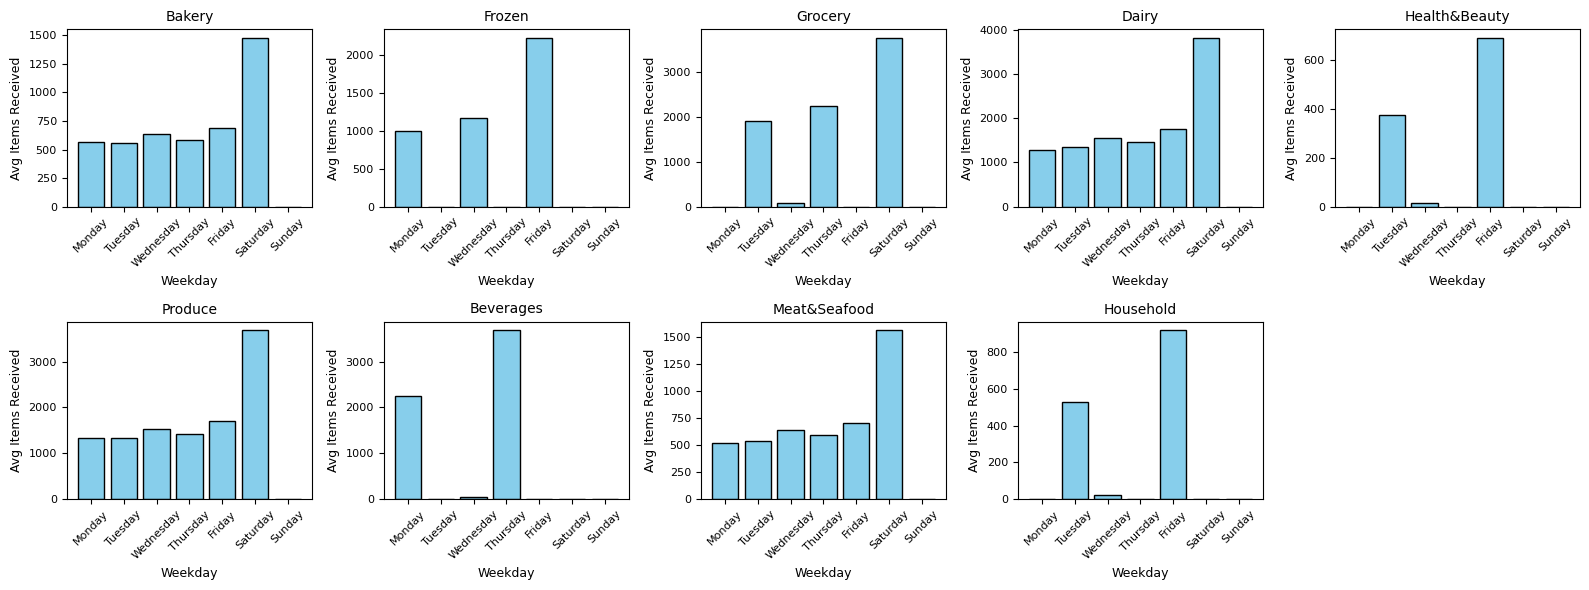

In [17]:
# # For each department, create a plot that shows the average number of items received on each weekday
# import matplotlib.pyplot as plt

# for department in Departments:
#     plt.figure(figsize=(5, 5))
#     plt.bar(Average_items_received_per_weekday_per_department[department].keys(), Average_items_received_per_weekday_per_department[department].values(), color='skyblue', edgecolor='black')
#     plt.title(f'Average Number of Items Received on Each Weekday for {department} Department')
#     plt.xlabel('Weekday')
#     plt.ylabel('Average Number of Items Received')
#     plt.xticks(rotation=45)
#     plt.tight_layout()
#     plt.show()

import matplotlib.pyplot as plt
import numpy as np

# Ordered list of the 9 departments (adjust to your actual Departments order)
depts = list(Departments)[:9]

# 2 rows: top row 5 cols, bottom row 4 cols
fig, axes = plt.subplots(2, 5, figsize=(16, 6))

# Flatten axes: first 5 = top row, last 5 = bottom row (last one hidden)
axes_flat = axes.flatten()

for i, department in enumerate(depts):
    ax = axes_flat[i]
    data = Average_items_received_per_weekday_per_department[department]
    ax.bar(data.keys(), data.values(), color='skyblue', edgecolor='black')
    ax.set_title(f'{department}', fontsize=10)
    ax.set_xlabel('Weekday', fontsize=9)
    ax.set_ylabel('Avg Items Received', fontsize=9)
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)

# Hide the unused 10th subplot (index 9)
for j in range(len(depts), len(axes_flat)):
    axes_flat[j].set_visible(False)

# Better: re-center the bottom 4 by leaving the 5th cell empty
plt.tight_layout()
plt.show()

In [18]:
# # For each weekday, create a plot that shows the average number of items received for each department
# for weekday in Weekdays:
#     plt.figure(figsize=(7.5, 5))
#     plt.bar([department for department in Departments], [Average_items_received_per_weekday_per_department[department][weekday] for department in Departments], color='skyblue', edgecolor='black')
#     plt.title(f'Average Number of Items Received for Each Department on {weekday}s')
#     plt.xlabel('Department')
#     plt.ylabel('Average Number of Items Received')
#     plt.xticks(rotation=45)
#     plt.tight_layout()
#     plt.show()

**Observation:** Beverages, household, and health & beauty items are only received only twice a week. Meanwhile, the grocery and frozen department only receive items three times a week. Meat & seafood, bakery, produce, and dary are receive every day excluding Sundays. This shows that the empty shelves are problably in the beverages, household, and health & beauty departments.
___

### 4. Determine which department (on sale or not) experiences the most shortages

In [19]:
# Create a list with the available departments
Departments = list({i.replace(" ", "") for i in Products['department']})

# Create a dictionary where the keys are the item ids and the values are the corresponding departments
item_department_dict = {row['item_id']: row['department'].replace(" ", "") for index, row in Products.iterrows()}

# Create a list of items for each department
department_items_dict = {department: [item for item in item_ids if item_department_dict[item] == department] for department in Departments}

# Create a new dataset that combines that adds the departments feature to the inventory dataset
Inventory_with_departments = Inventory.copy()
Inventory_with_departments['department'] = Inventory_with_departments['item_id'].map(item_department_dict)
Inventory_with_departments

,date,store_id,item_id,on_hand,received,shrink,department
0,2024-01-03,104,971509,100,100,1,Produce
1,2024-01-03,104,652089,220,220,3,Produce
2,2024-01-03,104,329628,100,100,0,Produce
3,2024-01-03,104,406789,24,24,1,Produce
4,2024-01-03,104,813467,24,24,0,Produce
...,...,...,...,...,...,...,...
8759995,2026-01-01,318,248758,6,0,0,Health&Beauty
8759996,2026-01-01,318,175134,8,0,0,Health&Beauty
8759997,2026-01-01,318,165350,19,0,0,Health&Beauty
8759998,2026-01-01,318,980056,0,0,0,Health&Beauty


In [20]:
# Create a list with the available departments
Departments = list({i.replace(" ", "") for i in Products['department']})

# Create a list with the available dates
dates = [i for i in Calendar['date']]

Items_with_shortages_per_day_for_a_department = Inventory_with_departments.loc[
    (Inventory_with_departments["store_id"] == store_ids[0]) &
    (Inventory_with_departments['date'] == dates[200]) &
    (Inventory_with_departments['department'] == Departments[0]) &
    (Inventory_with_departments['on_hand'] == 0)
]

Number_of_shortages_per_day_per_department = len(Items_with_shortages_per_day_for_a_department['date'])

In [21]:
shortages = (
    Inventory_with_departments
    .loc[
        (Inventory_with_departments["store_id"] == store_ids[0])
        & (Inventory_with_departments["on_hand"] == 0)
        & (Inventory_with_departments["date"].isin(dates))
        & (Inventory_with_departments["department"].isin(Departments))
    ]
    .groupby(["date", "department"])
    .size()                     # counts rows per (date, department)
    .unstack(fill_value=0)      # departments → columns
    .reindex(index=dates, columns=Departments, fill_value=0)  # fill missing combos
)

Number_of_shortages_per_day_per_department = shortages.to_dict(orient="index")

In [22]:
Weekdays = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
Average_Number_of_shortages_per_day_per_department = {}
for department in Departments:
    Average_Number_of_shortages_per_day_per_department[department] = {}
    for weekday in Weekdays:
        Number = [Number_of_shortages_per_day_per_department[date][department] for date in dates if pd.to_datetime(date).weekday() == Weekdays.index(weekday)]
        Average_Number_of_shortages_per_day_per_department[department][weekday] = int(sum(Number) / len(Number) if len(Number) > 0 else 0)

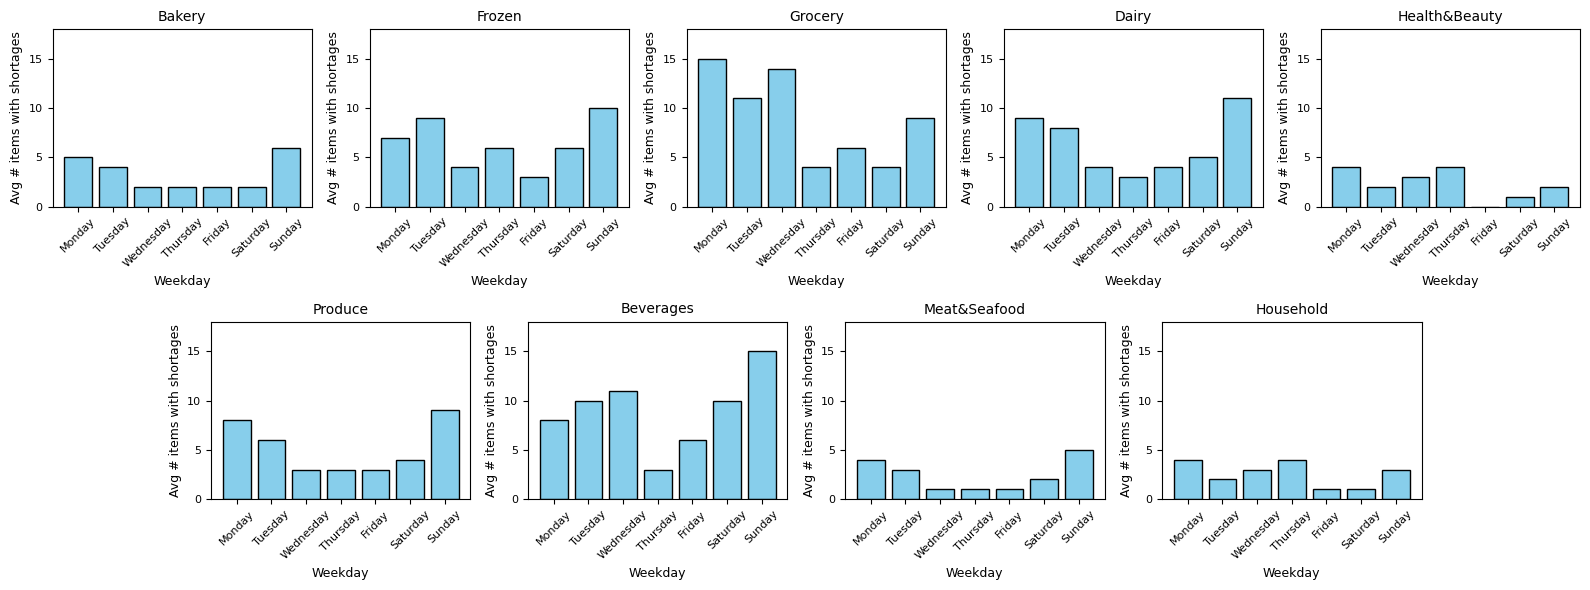

In [24]:
# import matplotlib.pyplot as plt

# fig, axes = plt.subplots(3, 3, figsize=(15, 15))
# axes = axes.flatten()  # makes it easy to index with a single loop

# for ax, department in zip(axes, Departments):
#     data = Average_Number_of_shortages_per_day_per_department[department]
#     ax.bar(
#         data.keys(),
#         data.values(),
#         color='skyblue',
#         edgecolor='black',
#     )
#     ax.set_title(f'Avg Shortages per Weekday — {department}', fontsize=10)
#     ax.set_xlabel('Weekday')
#     ax.set_ylabel('Avg # items with shortages')
#     ax.set_ylim(0, 18)                # <-- all y-axes fixed to 0–15
#     ax.tick_params(axis='x', rotation=45)

# # If Departments has fewer than 9 entries, hide unused axes
# for ax in axes[len(Departments):]:
#     ax.set_visible(False)

# fig.tight_layout()
# plt.show()

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

depts = list(Departments)[:9]
top_depts = depts[:5]
bottom_depts = depts[5:9]

fig = plt.figure(figsize=(16, 6))
# 2 rows x 20 cols. Each subplot spans 4 cols -> all equal width.
gs = GridSpec(2, 20, figure=fig)

top_axes = [fig.add_subplot(gs[0, i*4:(i+1)*4]) for i in range(5)]

# Bottom row: 4 plots of width 4 cols each, centered.
# Total bottom width = 16 cols; (20 - 16) / 2 = 2 cols of margin on each side.
bottom_axes = [fig.add_subplot(gs[1, 2 + i*4 : 2 + (i+1)*4]) for i in range(4)]

def plot_dept(ax, department):
    data = Average_Number_of_shortages_per_day_per_department[department]
    ax.bar(data.keys(), data.values(), color='skyblue', edgecolor='black')
    ax.set_title(department, fontsize=10)
    ax.set_xlabel('Weekday', fontsize=9)
    ax.set_ylabel('Avg # items with shortages', fontsize=9)
    ax.set_ylim(0, 18)
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)

for ax, d in zip(top_axes, top_depts):
    plot_dept(ax, d)
for ax, d in zip(bottom_axes, bottom_depts):
    plot_dept(ax, d)

for ax in (top_axes + bottom_axes)[len(depts):]:
    ax.set_visible(False)

fig.tight_layout()
plt.savefig('shortages_weekday_plots.png', dpi=200, bbox_inches='tight')
plt.show()

**Observation:** The plots show that items from each department often experience shortages on Monday, Tuesdays, and Sundays. This is likely due to the fixed delivery schedules.
___